# Step 1 — Data cleaning & preprocessing

**Project question:** *Are friend communities also taste communities?*
(DTU 02807 Computational Tools for Data Science, Yelp Open Dataset)

This notebook covers **step 1 of our pipeline** and records every step, the reason for it and what we found, so everyone in the group (and the graders) can follow and reproduce the cleaning.

| Pipeline step | What it does here |
|---|---|
| 1a | Load and check the **business** file; normalise city names; parse `categories`; flag **restaurants** (our scope). |
| 1b | Stream the 5.3 GB **review** file once and keep only the columns we need (cached as Parquet). |
| 1c | **Choose a single city**, using evidence: how many active restaurant reviewers and how large a friend graph each city gives. |
| 1d | **Filter**: city → restaurants → one review per (user, restaurant) → users with ≥ 10 restaurant reviews → largest connected component (LCC) of the friendship graph. Row counts are logged after every filter. |
| 1e | **Normalise star ratings per user** (subtract the user's mean) and mark **positive ratings** (stars ≥ 3.5). |
| 1f | Quick exploration of the cleaned data. |
| 1g | Sanity checks, then **save the clean tables** to `data/processed/` for steps 2–5. |

**Outputs:** four Parquet files (users, friend edges, reviews, restaurants) plus a JSON summary of the cleaning. They are described in section 1g.

## Before you run: setup (5 minutes + download)

**1. Get the data.** Download the **Yelp Open Dataset (JSON)** from <https://business.yelp.com/data/resources/open-dataset/> and accept its terms. We cannot share the data ourselves. Extract the archive. Only **3 of its 5 files** are needed:

- `yelp_academic_dataset_business.json`
- `yelp_academic_dataset_review.json`
- `yelp_academic_dataset_user.json`

Tips and check-ins are not used.

**2. Put the files here.** Create this folder layout. Only `data/raw/` needs to be created by hand: `data/processed/` and `figures/` are created by the notebook.
```
project/
├── notebooks/
│   └── 01_data_cleaning.ipynb      <- this notebook
└── data/
    └── raw/                        <- the 3 JSON files above (≈ 8.8 GB)
```
If the files are already somewhere else, you can leave them there and set the environment variable `YELP_DATA_RAW` to that folder before starting Jupyter, e.g. `export YELP_DATA_RAW="/path/to/yelp_dataset"`.

**3. Install the packages** (Python ≥ 3.10):
```bash
pip install pandas numpy pyarrow networkx matplotlib jupyterlab
```

**4. Run.** `jupyter lab notebooks/01_data_cleaning.ipynb`, then *Run → Run All Cells*.
- The first run streams the raw files and takes about **2 minutes**. It writes caches to `data/processed/`.
- After that, a re-run takes under 30 seconds.
- The large raw files are never loaded whole, so a laptop with 8 GB of RAM is enough.
- If the data folder is not found, the setup cell stops with a message saying where it looked.

## 0. Setup

Imports, paths, the random seed and the **parameters of the cleaning**. Every threshold lives in this one cell, so a change made here propagates through the whole notebook.

The notebook finds the raw data in this order: the environment variable `YELP_DATA_RAW`, then `data/raw/`, then `Yelp JSON/yelp_dataset/` (where the files currently sit on our machines).

In [1]:
import difflib
import json
import os
import platform
import random
import time
from collections import Counter
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker
import networkx as nx
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.parquet as pq

# ---------------- Paths (relative to the project root) ----------------
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

def find_data_raw() -> Path:
    # First folder that contains the Yelp business file.
    candidates = [os.environ.get("YELP_DATA_RAW"),
                  PROJECT_ROOT / "data" / "raw",
                  PROJECT_ROOT / "Yelp JSON" / "yelp_dataset"]
    for c in candidates:
        if c and (Path(c) / "yelp_academic_dataset_business.json").exists():
            return Path(c).resolve()
    looked = "\n  ".join(str(c) for c in candidates if c)
    raise FileNotFoundError("Yelp JSON files not found. Put the 3 files in data/raw/ or set YELP_DATA_RAW "
                            f"(see 'Before you run' at the top). Looked in:\n  {looked}")

DATA_RAW = find_data_raw()
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"
FIGURES = PROJECT_ROOT / "figures"
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
raw_file = lambda name: DATA_RAW / f"yelp_academic_dataset_{name}.json"

# ---------------- Cleaning parameters (change them here only) ----------------
BUSINESS_CATEGORY = "Restaurants"  # keep only businesses with this Yelp category (None = all businesses)
MIN_REVIEWS = 10                   # keep users with at least this many reviewed restaurants in the chosen city
POSITIVE_MIN_STARS = 3.5           # a review is "positive" if stars >= 3.5 (review stars are whole numbers -> 4 or 5)
N_CANDIDATE_CITIES = 8             # how many cities we compare before choosing one
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# ---------------- Display & plotting style ----------------
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"pyarrow {pa.__version__} | networkx {nx.__version__} | matplotlib {matplotlib.__version__}")
print(f"PROJECT_ROOT   = {PROJECT_ROOT}")
print(f"DATA_RAW       = {DATA_RAW}")
print(f"DATA_PROCESSED = {DATA_PROCESSED}")

Python 3.11.13 | pandas 2.3.2 | numpy 2.1.3 | pyarrow 21.0.0 | networkx 3.5 | matplotlib 3.10.6
PROJECT_ROOT   = /Users/viktor/Desktop/masters/DTU_2026_27/1st_semester/Computational_Tools_for_Data_Science/project
DATA_RAW       = /Users/viktor/Desktop/masters/DTU_2026_27/1st_semester/Computational_Tools_for_Data_Science/project/data/raw
DATA_PROCESSED = /Users/viktor/Desktop/masters/DTU_2026_27/1st_semester/Computational_Tools_for_Data_Science/project/data/processed


## 1a. Businesses: load, check and normalise city names

The business file is small (≈ 119 MB, 150k rows), so we load it whole.

**Why normalise city names?** The dataset has no "metro area" field, only a free-text `city` typed in by the business owners. The same city can appear as `"Philadelphia"`, `"philadelphia"` or `"Philadelphia "`. We collapse extra whitespace and capitalisation, and identify a city by **(city, state)**, because some city names exist in more than one state.

We also turn `categories` (one comma-separated string) into a Python list. Steps 3 and 4 need it as a list.

**Why restaurants only?** Yelp covers very different kinds of business: restaurants, but also dentists, car repair, hair salons, plumbers and so on. A shared dentist says little about shared *taste*, and users who review many services would look similar for reasons that have nothing to do with taste. Restricting to businesses tagged **`Restaurants`** (set by `BUSINESS_CATEGORY` in the setup cell) makes "taste" concrete: *which restaurants and cuisines a user likes*. The cuisine categories (`Italian`, `Thai`, `Vegan`, …) then become natural items for steps 3 and 4.

In [2]:
t0 = time.perf_counter()
biz = pd.read_json(raw_file("business"), lines=True)
print(f"Loaded {len(biz):,} businesses x {biz.shape[1]} columns in {time.perf_counter() - t0:.1f} s")

# --- basic quality checks ---
print("Duplicate business_id:", biz.business_id.duplicated().sum())
print("\nMissing values per column (only columns with any):")
na = biz.isna().sum()
print(na[na > 0].to_string())

Loaded 150,346 businesses x 14 columns in 1.5 s
Duplicate business_id: 0

Missing values per column (only columns with any):
attributes    13744
categories      103
hours         23223


In [3]:
def normalize_city(s):
    # 'philadelphia ' -> 'Philadelphia' (collapse whitespace, title case).
    if not isinstance(s, str):
        return None
    return " ".join(s.split()).title()

biz["city_norm"] = biz["city"].map(normalize_city)
biz["state"] = biz["state"].str.strip().str.upper()
biz["city_key"] = biz["city_norm"] + ", " + biz["state"]

# categories: "Pizza, Restaurants" -> ["Pizza", "Restaurants"]; missing -> []
biz["categories_list"] = biz["categories"].map(
    lambda s: [c.strip() for c in s.split(",") if c.strip()] if isinstance(s, str) else [])

print(f"Distinct raw city strings      : {biz.city.nunique():,}")
print(f"Distinct normalised (city,state): {biz.city_key.nunique():,}")
print(f"Businesses without categories  : {(biz.categories_list.str.len() == 0).sum():,}")
print(f"Distinct categories            : {len({c for cs in biz.categories_list for c in cs}):,}")

# Scope: restaurants only (every business whose category list contains BUSINESS_CATEGORY)
biz["in_scope"] = biz["categories_list"].map(lambda cs: BUSINESS_CATEGORY is None or BUSINESS_CATEGORY in cs)
scope_ids = set(biz.loc[biz.in_scope, "business_id"])
print(f"Businesses tagged '{BUSINESS_CATEGORY}'   : {len(scope_ids):,} ({len(scope_ids) / len(biz):.1%})")

(biz.groupby("city_key").agg(businesses=("business_id", "size"), restaurants=("in_scope", "sum"))
    .sort_values("restaurants", ascending=False).head(15))

Distinct raw city strings      : 1,416
Distinct normalised (city,state): 1,283
Businesses without categories  : 103
Distinct categories            : 1,311
Businesses tagged 'Restaurants'   : 52,268 (34.8%)


,businesses,restaurants
city_key,,
"Philadelphia, PA",14575,5855
"Tampa, FL",9067,2967
"Indianapolis, IN",7545,2863
"Nashville, TN",6978,2505
"Tucson, AZ",9261,2469
"New Orleans, LA",6215,2261
"Edmonton, AB",5056,2168
"Saint Louis, MO",4833,1790
"Reno, NV",5937,1288


> **What we found.**
> - 150,346 businesses with no duplicate IDs. Normalisation merged the 1,416 raw city strings into 1,283 (city, state) pairs.
> - **52,268 businesses (35%) are restaurants.** **Philadelphia, PA** has the most of them by far: 5,855 restaurants, about twice as many as Tampa (2,967).
> - Only 103 businesses have no categories, and they are excluded anyway because they cannot be identified as restaurants.
> - `attributes` and `hours` have missing values, but this project does not use them.

## 1b. Reviews: one streaming pass, keep only what we need

The review file is **5.3 GB with ≈ 7M reviews**, and most of its bytes are the review `text`, which this project does not use. We read it **line by line** (one JSON object per line). From each review we keep only `review_id, user_id, business_id, stars, date`, and write the result to Parquet in chunks of 500k rows, so memory use stays small.

The result is cached as `data/processed/reviews_slim_all.parquet` (a few hundred MB). If that file already exists, the cell skips the slow pass. Delete the file to force a re-run.

In [4]:
REVIEWS_SLIM = DATA_PROCESSED / "reviews_slim_all.parquet"
REVIEW_SCHEMA = pa.schema([("review_id", pa.string()), ("user_id", pa.string()),
                           ("business_id", pa.string()), ("stars", pa.float32()),
                           ("date", pa.timestamp("s"))])

def stream_reviews_to_parquet(src: Path, dst: Path, chunk: int = 500_000) -> Counter:
    # Stream the review JSON-lines file and write the slim columns to Parquet.
    stats = Counter()
    cols = {k: [] for k in ("review_id", "user_id", "business_id", "stars", "date")}
    tmp = dst.with_suffix(".tmp")
    writer = pq.ParquetWriter(tmp, REVIEW_SCHEMA, compression="zstd")

    def flush():
        if not cols["review_id"]:
            return
        dates = pc.strptime(pa.array(cols["date"], pa.string()), format="%Y-%m-%d %H:%M:%S", unit="s")
        table = pa.table({"review_id": cols["review_id"], "user_id": cols["user_id"],
                          "business_id": cols["business_id"],
                          "stars": pa.array(cols["stars"], pa.float32()), "date": dates},
                         schema=REVIEW_SCHEMA)
        writer.write_table(table)
        for v in cols.values():
            v.clear()

    with open(src, "rb") as f:
        for line in f:
            stats["lines"] += 1
            try:
                r = json.loads(line)
            except json.JSONDecodeError:
                stats["bad_json"] += 1
                continue
            for k in cols:
                v = r.get(k)
                if v is None:
                    stats[f"missing_{k}"] += 1
                cols[k].append(v)
            if len(cols["review_id"]) >= chunk:
                flush()
    flush()
    writer.close()
    tmp.rename(dst)  # only appears under its final name once complete
    return stats

if REVIEWS_SLIM.exists():
    print(f"Using cached {REVIEWS_SLIM.name} ({REVIEWS_SLIM.stat().st_size / 1e6:.0f} MB)")
else:
    t0 = time.perf_counter()
    stream_stats = stream_reviews_to_parquet(raw_file("review"), REVIEWS_SLIM)
    print(f"Streamed {stream_stats['lines']:,} lines in {time.perf_counter() - t0:.0f} s -> "
          f"{REVIEWS_SLIM.stat().st_size / 1e6:.0f} MB")
    print("Problems found while parsing:", {k: v for k, v in stream_stats.items() if k != "lines"} or "none")

Streamed 6,990,280 lines in 28 s -> 305 MB
Problems found while parsing: none


Next we load the slim table and run **quality checks on all reviews**: unique review IDs, missing values, valid star values, date range, and reviews that point to a business missing from the business file.

To save memory, user and business IDs are loaded as pandas `category` dtype. Each distinct ID is then stored once and the rows hold small integer codes.

In [5]:
t0 = time.perf_counter()
tbl = pq.read_table(REVIEWS_SLIM)
n_reviews_raw = tbl.num_rows
print(f"Reviews                 : {n_reviews_raw:,}")
print(f"Distinct review_id      : {pc.count_distinct(tbl['review_id']).as_py():,}")
print("Null values per column  :", {c: tbl[c].null_count for c in tbl.column_names})

reviews_all = tbl.drop_columns(["review_id"]).to_pandas(strings_to_categorical=True)
del tbl
print(f"Loaded into pandas in {time.perf_counter() - t0:.1f} s, "
      f"{reviews_all.memory_usage(deep=True).sum() / 1e6:.0f} MB in memory")

print("\nStar values:", reviews_all.stars.value_counts().sort_index().to_dict())
print("Date range :", reviews_all.date.min(), "->", reviews_all.date.max())
unknown_biz = ~reviews_all.business_id.isin(biz.business_id)
print(f"Reviews of businesses not in business file: {unknown_biz.sum():,}")
print(f"Distinct users with >= 1 review: {reviews_all.user_id.nunique():,}")

Reviews                 : 6,990,280
Distinct review_id      : 6,990,280
Null values per column  : {'review_id': 0, 'user_id': 0, 'business_id': 0, 'stars': 0, 'date': 0}
Loaded into pandas in 3.1 s, 381 MB in memory

Star values: {1.0: 1069561, 2.0: 544240, 3.0: 691934, 4.0: 1452918, 5.0: 3231627}
Date range : 2005-02-16 03:23:22 -> 2022-01-19 19:48:45
Reviews of businesses not in business file: 0
Distinct users with >= 1 review: 1,987,929


> **What we found.** The review file is clean:
> - 6,990,280 reviews; every `review_id` is unique.
> - No missing values and no malformed lines.
> - Stars are whole numbers from 1 to 5, and dates run from Feb 2005 to Jan 2022.
> - Every review points to a known business.
>
> Ratings are strongly skewed: **46% of all reviews give 5 stars**. This is one reason to normalise per user (section 1e).
>
> One quirk: the reviews contain 1,987,929 distinct users, while the user file has 1,987,897 records, so **32 reviewers have no profile**. Section 1g checks that none of our final users is affected.

## 1c. Choosing the city

Filtering to **one city** keeps the problem a manageable size. It also makes the friend graph meaningful: friends in the same city can visit the same businesses, so shared taste is actually observable.

A city is only useful to us if, **after** our filters, it still has a large, connected friend graph of active reviewers. All counts below therefore use **restaurant reviews only**. For each city we compute:
1. restaurant reviews, restaurants and users (from the review file);
2. **users with ≥ `MIN_REVIEWS` distinct reviewed restaurants _in that city_**. We count reviews inside the dataset and the city, not Yelp's `review_count` field. That field includes reviews that are not in this dataset, are in other cities or are of other kinds of business, which tell us nothing about restaurant taste here;
3. for the top `N_CANDIDATE_CITIES` cities by (2), the **friend graph among those users** and the size of its **largest connected component (LCC)**. This is the number of users we would actually analyse.

In [6]:
t0 = time.perf_counter()
# City of every in-scope business; reviews of other businesses get no city and drop out of the counts.
city_of_biz = biz.loc[biz.in_scope].set_index("business_id")["city_key"]
reviews_all["city_key"] = reviews_all["business_id"].map(city_of_biz).astype("category")
print(f"Restaurant reviews in the whole dataset: {reviews_all.city_key.notna().sum():,} "
      f"({reviews_all.city_key.notna().mean():.1%} of all reviews)")

# distinct restaurants reviewed per (city, user)
user_city = (reviews_all[["city_key", "user_id", "business_id"]].drop_duplicates()
             .groupby(["city_key", "user_id"], observed=True).size().rename("n_biz").reset_index())

g = reviews_all.groupby("city_key", observed=True)
city_stats = pd.DataFrame({"reviews": g.size(),
                           "restaurants": g["business_id"].nunique(),
                           "users": g["user_id"].nunique()})
city_stats[f"users_ge{MIN_REVIEWS}"] = (user_city[user_city.n_biz >= MIN_REVIEWS]
                                        .groupby("city_key", observed=True).size())
city_stats = city_stats.fillna(0).astype(int).sort_values(f"users_ge{MIN_REVIEWS}", ascending=False)
print(f"Computed in {time.perf_counter() - t0:.1f} s")
city_stats.head(15)

Restaurant reviews in the whole dataset: 4,724,471 (67.6% of all reviews)
Computed in 3.1 s


,reviews,restaurants,users,users_ge10
city_key,,,,
"Philadelphia, PA",687553,5855,209578,10731
"New Orleans, LA",476565,2261,201869,4836
"Tampa, FL",303691,2967,114463,4065
"Indianapolis, IN",250642,2863,77481,3975
"Tucson, AZ",249813,2469,81381,3793
"Nashville, TN",325775,2505,139700,3637
"Reno, NV",200617,1288,76144,2712
"Saint Louis, MO",178452,1790,69849,2304
"Santa Barbara, CA",162430,768,88108,1316


> **What we found.** Restaurants account for **68% of all reviews** (4.72M). **Philadelphia** has the most restaurant reviews (688k) and by far the most active restaurant reviewers: 10,731 users with ≥ 10 restaurant reviews, more than twice the runner-up New Orleans (4,836). The activity filter is harsh everywhere. Only about 5% of a city's restaurant reviewers have ≥ 10 reviews there, because most reviewers are occasional users or tourists.

To measure the friend graphs we need the `friends` field of the user file (3.4 GB, ≈ 2M users). We stream it once. We keep the full record (friend list plus a few profile fields) **only for users who pass the review threshold in one of the candidate cities**. For everyone else we only update global counters.

The friend list is a comma-separated string of user IDs, or the literal string `"None"`. The kept records are cached as `data/processed/users_candidates.parquet`.

In [7]:
candidate_cities = list(city_stats.index[:N_CANDIDATE_CITIES])
active = user_city[(user_city.n_biz >= MIN_REVIEWS) & user_city.city_key.isin(candidate_cities)]
candidate_users = {c: set(active.loc[active.city_key == c, "user_id"].astype(str)) for c in candidate_cities}
all_candidates = set().union(*candidate_users.values())
print("Candidate cities:", candidate_cities)
print(f"Active users across candidate cities: {len(all_candidates):,}")

USERS_CAND = DATA_PROCESSED / "users_candidates.parquet"
KEEP_USER_FIELDS = ["user_id", "review_count", "yelping_since", "fans", "average_stars"]

def parse_friends(s):
    if not s or s == "None":
        return []
    return [x.strip() for x in s.split(",") if x.strip()]

def stream_users(src: Path, keep_ids: set):
    # Stream the user file; return kept records and global counters.
    rows, stats = [], Counter()
    with open(src, "rb") as f:
        for line in f:
            r = json.loads(line)
            stats["users"] += 1
            friends = parse_friends(r.get("friends"))
            stats["users_without_friends"] += (len(friends) == 0)
            stats["friend_links_listed"] += len(friends)
            if r["user_id"] in keep_ids:
                rec = {k: r.get(k) for k in KEEP_USER_FIELDS}
                rec["friends"] = friends
                rows.append(rec)
    return pd.DataFrame(rows), stats

USER_STATS = DATA_PROCESSED / "users_global_stats.json"
if (USERS_CAND.exists() and USER_STATS.exists()
        and set(pd.read_parquet(USERS_CAND, columns=["user_id"]).user_id) >= all_candidates):
    users_cand = pd.read_parquet(USERS_CAND)
    user_stats = json.loads(USER_STATS.read_text())
    print(f"Using cached {USERS_CAND.name}: {len(users_cand):,} users")
else:
    t0 = time.perf_counter()
    users_cand, user_stats = stream_users(raw_file("user"), all_candidates)
    users_cand.to_parquet(USERS_CAND, index=False)
    USER_STATS.write_text(json.dumps(dict(user_stats)))
    print(f"Streamed {user_stats['users']:,} users in {time.perf_counter() - t0:.0f} s; kept {len(users_cand):,}")
print(f"Users in the user file: {user_stats['users']:,}; with no friends at all: "
      f"{user_stats['users_without_friends']:,} ({user_stats['users_without_friends'] / user_stats['users']:.1%})")

missing = all_candidates - set(users_cand.user_id)
print(f"Active users missing from the user file: {len(missing):,}")
friends_of = dict(zip(users_cand.user_id, users_cand.friends))

Candidate cities: ['Philadelphia, PA', 'New Orleans, LA', 'Tampa, FL', 'Indianapolis, IN', 'Tucson, AZ', 'Nashville, TN', 'Reno, NV', 'Saint Louis, MO']
Active users across candidate cities: 35,430
Streamed 1,987,897 users in 21 s; kept 35,430
Users in the user file: 1,987,897; with no friends at all: 878,551 (44.2%)
Active users missing from the user file: 0


> **What we found.** 44% of all Yelp users list no friends at all. Every active user in the candidate cities has a record in the user file.

For each candidate city we build the **undirected friendship graph among its active users**. An edge links two users who both pass the threshold in that city and list each other (or one lists the other) as friends. We also check whether friendships are **symmetric** in the data, i.e. whether *u* listing *v* implies *v* lists *u*.

In [8]:
def build_friend_graph(user_ids, friends_of):
    # Undirected friendship graph restricted to `user_ids`, plus the share of reciprocated links.
    S = set(user_ids)
    directed = {(u, v) for u in S for v in friends_of.get(u, ()) if v in S and v != u}
    reciprocated = sum((v, u) in directed for (u, v) in directed) / max(len(directed), 1)
    G = nx.Graph()
    G.add_nodes_from(S)
    G.add_edges_from(directed)  # (u,v) and (v,u) collapse into one undirected edge
    return G, reciprocated

t0 = time.perf_counter()
rows = []
for c in candidate_cities:
    G, recip = build_friend_graph(candidate_users[c], friends_of)
    lcc = max(nx.connected_components(G), key=len)
    rows.append({"city": c, "active_users": G.number_of_nodes(), "friend_edges": G.number_of_edges(),
                 "isolated_users": nx.number_of_isolates(G), "reciprocated_links": recip,
                 "lcc_users": len(lcc), "lcc_share": len(lcc) / G.number_of_nodes(),
                 "lcc_edges": G.subgraph(lcc).number_of_edges(),
                 "lcc_avg_degree": 2 * G.subgraph(lcc).number_of_edges() / len(lcc)})
candidates = pd.DataFrame(rows).set_index("city").sort_values("lcc_users", ascending=False)
print(f"Built {len(candidate_cities)} graphs in {time.perf_counter() - t0:.1f} s")
candidates.style.format({"reciprocated_links": "{:.1%}", "lcc_share": "{:.1%}", "lcc_avg_degree": "{:.1f}",
                         "active_users": "{:,}", "friend_edges": "{:,}", "isolated_users": "{:,}",
                         "lcc_users": "{:,}", "lcc_edges": "{:,}"})

Built 8 graphs in 1.2 s


,active_users,friend_edges,isolated_users,reciprocated_links,lcc_users,lcc_share,lcc_edges,lcc_avg_degree
city,,,,,,,,
"Philadelphia, PA","10,731","67,651","2,725",100.0%,"7,946",74.0%,"67,620",17.0
"Indianapolis, IN","3,975","29,036",545,100.0%,"3,424",86.1%,"29,033",17.0
"New Orleans, LA","4,836","26,902","1,407",100.0%,"3,416",70.6%,"26,895",15.7
"Tampa, FL","4,065","34,945",957,100.0%,"3,094",76.1%,"34,938",22.6
"Tucson, AZ","3,793","12,076","1,480",100.0%,"2,289",60.3%,"12,064",10.5
"Nashville, TN","3,637","11,477","1,349",100.0%,"2,250",61.9%,"11,457",10.2
"Reno, NV","2,712","21,113",533,100.0%,"2,175",80.2%,"21,111",19.4
"Saint Louis, MO","2,304","17,085",473,100.0%,"1,827",79.3%,"17,083",18.7


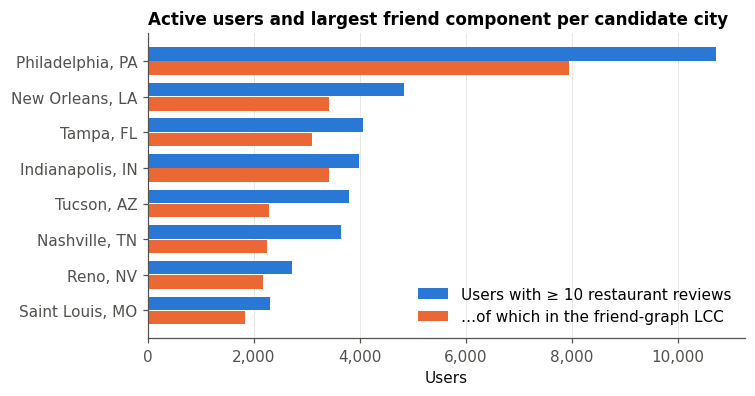

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.6))
order = candidates.sort_values("active_users")
y = np.arange(len(order))
ax.barh(y + 0.2, order.active_users, height=0.38, color=BLUE, label=f"Users with ≥ {MIN_REVIEWS} restaurant reviews")
ax.barh(y - 0.2, order.lcc_users, height=0.38, color=ORANGE, label="…of which in the friend-graph LCC")
ax.set_yticks(y, order.index)
ax.set_xlabel("Users")
ax.xaxis.set_major_formatter(matplotlib.ticker.StrMethodFormatter("{x:,.0f}"))
ax.set_title("Active users and largest friend component per candidate city")
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="y", visible=False)
fig.savefig(FIGURES / "01_city_candidates.png")
plt.show()

> **What we found.**
> - **Friendships are symmetric**: 100% of links are reciprocated in every city, so we can safely treat the friend graph as undirected.
> - In every city, 60–86% of the active users fall into one large connected component. The rest are almost all **isolated users**, people with no friend among the city's active restaurant reviewers.
> - Philadelphia's LCC (≈ 7.9k users, ≈ 68k friendships, mean degree 17) is **more than twice as large as any other city's**. Indianapolis and New Orleans come next with about 3.4k each.

**Decision.** We pick the city whose **largest connected component is largest**: it gives the most users for whom both questions, friend community and taste community, can be answered. The cell below makes the choice from the table above. To try another city, override `CITY` there and re-run everything below it.

We also check for **misspelled variants** of the chosen city name in the same state that the simple normalisation did not merge, and merge the ones that clearly refer to the same city.

In [10]:
CITY = candidates["lcc_users"].idxmax()   # override here, e.g. CITY = "Tampa, FL"
city_name, city_state = CITY.rsplit(", ", 1)
CITY_SLUG = f"{city_name}_{city_state}".lower().replace(" ", "_")
print(f"Chosen city: {CITY}   (file prefix: {CITY_SLUG})\n")

# spelling variants in the same state that normalisation did not merge
same_state = biz[biz.state == city_state]
variants = difflib.get_close_matches(city_name, same_state.city_norm.dropna().unique(), n=15, cutoff=0.75)
var_counts = same_state[same_state.city_norm.isin(variants)].groupby("city_norm").size().sort_values(ascending=False)
print("Close spellings in the same state (businesses):")
print(var_counts.to_string())

# All of these are the same city (typos, "Pa" suffix, a neighbourhood name), so we merge them.
# If you override CITY, inspect this list and remove any name that is really a different place.
CITY_NAMES = set(variants)
city_biz_df = biz[(biz.state == city_state) & biz.city_norm.isin(CITY_NAMES)]
city_biz = set(city_biz_df.business_id)
print(f"\nBusinesses in {CITY} after merging variants: {len(city_biz):,} "
      f"(+{len(city_biz) - (biz.city_key == CITY).sum()} from variant spellings)")

Chosen city: Philadelphia, PA   (file prefix: philadelphia_pa)

Close spellings in the same state (businesses):
city_norm
Philadelphia         14575
Philadephia              7
Philadelphia Pa          2
Philadelphila            1
Philiadelphia            1
Philiidelphia            1
West Philadelphia        1

Businesses in Philadelphia, PA after merging variants: 14,588 (+13 from variant spellings)


> **What we found.** We choose **Philadelphia, PA**. Its spelling variants (`Philadephia`, `Philadelphia Pa`, `Philiadelphia`, …, and the neighbourhood name `West Philadelphia`) add only 13 businesses, of which a single restaurant. We merge them anyway for correctness, although the effect is negligible.

## 1d. Filtering the chosen city

We apply the filters **in this order** and log reviews / users / businesses after each one:

1. **City**: reviews of businesses in the chosen city (including the merged spelling variants).
2. **Restaurants**: keep only reviews of businesses tagged `Restaurants` (see 1a).
3. **One review per (user, restaurant)**: a user can review the same restaurant more than once. For "the set of restaurants a user reviewed" a repeat adds nothing, and it would let a user reach the threshold by reviewing one place ten times. We keep the **most recent** review, which is the user's latest opinion.
4. **Users with ≥ `MIN_REVIEWS` restaurant reviews**: users with very few reviews have tiny taste sets. Their Jaccard similarities are noisy, and their mean rating (used for normalisation) is unreliable.
5. **Largest connected component of the friendship graph** among the remaining users. Communities can only be detected among connected users. Isolated users and tiny islands carry no friend-community information.

This order matters:
- The restaurant filter comes **before** the activity filter, so the 10 reviews must all be restaurant reviews.
- The friend graph is built **after** the activity filter, so every node in the final graph is an active restaurant reviewer.
- Step 5 only removes users and never removes reviews of kept users, so everyone in the LCC still has ≥ `MIN_REVIEWS` reviews. No second filtering pass is needed.

In [11]:
funnel = []
def log_step(step, reviews, n_edges=None):
    funnel.append({"step": step, "reviews": len(reviews), "users": reviews.user_id.nunique(),
                   "businesses": reviews.business_id.nunique(), "friend_edges": n_edges})

log_step("0. all reviews (whole dataset)", reviews_all)

# 1. city -------------------------------------------------------------
rv = reviews_all[reviews_all.business_id.isin(list(city_biz))].drop(columns="city_key").copy()
rv["user_id"] = rv["user_id"].astype(str)
rv["business_id"] = rv["business_id"].astype(str)
log_step(f"1. reviews in {CITY}", rv)

# 2. restaurants only ----------------------------------------------------
rv = rv[rv.business_id.isin(scope_ids)].reset_index(drop=True)
log_step(f"2. only '{BUSINESS_CATEGORY}'", rv)

# 3. one review per (user, business): keep the most recent --------------
dup_pairs = rv.duplicated(["user_id", "business_id"], keep=False)
print(f"Reviews that are repeats of the same (user, restaurant): {dup_pairs.sum():,} "
      f"in {rv[dup_pairs].groupby(['user_id', 'business_id']).ngroups:,} pairs")
rv = (rv.sort_values(["user_id", "business_id", "date"])
        .drop_duplicates(["user_id", "business_id"], keep="last")
        .reset_index(drop=True))
log_step("3. one review per (user, restaurant)", rv)

# 4. users with >= MIN_REVIEWS reviews -----------------------------------
n_per_user = rv.groupby("user_id").size()
active_users = set(n_per_user[n_per_user >= MIN_REVIEWS].index)
rv = rv[rv.user_id.isin(active_users)].reset_index(drop=True)
log_step(f"4. users with >= {MIN_REVIEWS} restaurant reviews", rv)

# Active users whose friend list we have not read yet (e.g. pushed over the threshold by the
# merged spelling variants, or a CITY override): stream the user file once more for them.
missing_profiles = active_users - set(users_cand.user_id)
if missing_profiles:
    extra, _ = stream_users(raw_file("user"), missing_profiles)
    users_cand = pd.concat([users_cand, extra], ignore_index=True)
    users_cand.to_parquet(USERS_CAND, index=False)
    friends_of.update(zip(extra.user_id, extra.friends))
print(f"Active users whose profile had to be fetched additionally: {len(missing_profiles):,}")

# 5. friendship graph + largest connected component ----------------------
G_all, recip = build_friend_graph(active_users, friends_of)
components = sorted(nx.connected_components(G_all), key=len, reverse=True)
lcc_nodes = components[0]
G = G_all.subgraph(lcc_nodes).copy()
rv = rv[rv.user_id.isin(lcc_nodes)].reset_index(drop=True)
log_step("5. largest connected component", rv, n_edges=G.number_of_edges())

funnel_df = pd.DataFrame(funnel).set_index("step")
funnel_df["users_kept_vs_prev"] = funnel_df.users / funnel_df.users.shift()
funnel_df.style.format({"reviews": "{:,}", "users": "{:,}", "businesses": "{:,}",
                        "friend_edges": lambda v: "" if pd.isna(v) else f"{int(v):,}",
                        "users_kept_vs_prev": lambda v: "" if pd.isna(v) else f"{v:.1%}"})

Reviews that are repeats of the same (user, restaurant): 40,876 in 19,331 pairs
Active users whose profile had to be fetched additionally: 1


,reviews,users,businesses,friend_edges,users_kept_vs_prev
step,,,,,
0. all reviews (whole dataset),"6,990,280","1,987,929","150,346",,
"1. reviews in Philadelphia, PA","968,388","280,107","14,588",,14.1%
2. only 'Restaurants',"687,827","209,694","5,856",,74.9%
"3. one review per (user, restaurant)","666,282","209,694","5,856",,100.0%
4. users with >= 10 restaurant reviews,"295,175","10,732","5,797",,5.1%
5. largest connected component,"251,375","7,947","5,759","67,622",74.0%


> **What we found.** Reading the funnel row by row:
> 1. **City**: Philadelphia holds 968,388 reviews, 14% of the dataset.
> 2. **Restaurants**: 687,827 of those reviews (71%) are of 5,856 restaurants. 75% of the city's reviewers have reviewed at least one restaurant.
> 3. **Repeats**: 40,876 reviews are repeats of the same (user, restaurant), in 19,331 pairs. Keeping one review per pair removes 21,545 reviews.
> 4. **Activity**: the ≥ 10 restaurant reviews filter is the strongest. It keeps only **5.1% of users** (10,732 of 209,694), but **44% of the reviews**, because the activity is concentrated in a small core of heavy users.
> 5. **LCC**: keeps 74% of the active users and 85% of their reviews.
>
> **Final dataset: 7,947 users, 67,622 friendships, 251,375 reviews and 5,759 restaurants.** Every user is an active restaurant reviewer connected to all the others through friendships.

What the friend graph looked like **before** taking the LCC, i.e. which users step 5 removes:

In [12]:
sizes = pd.Series([len(c) for c in components])
print(f"Active users                 : {G_all.number_of_nodes():,}")
print(f"Friend edges among them      : {G_all.number_of_edges():,}")
print(f"Reciprocated friend links    : {recip:.1%}  (share of u->v links where v->u is also listed)")
print(f"Connected components         : {len(components):,}")
print(f"  of which isolated users    : {(sizes == 1).sum():,}")
print(f"  largest component          : {sizes.iloc[0]:,} users ({sizes.iloc[0] / sizes.sum():.1%})")
print(f"  second largest component   : {sizes.iloc[1] if len(sizes) > 1 else 0:,} users")
print("Component size distribution (size: count):", sizes.value_counts().sort_index().head(10).to_dict())

Active users                 : 10,732
Friend edges among them      : 67,653
Reciprocated friend links    : 100.0%  (share of u->v links where v->u is also listed)
Connected components         : 2,755
  of which isolated users    : 2,725
  largest component          : 7,947 users (74.0%)
  second largest component   : 3 users
Component size distribution (size: count): {1: 2725, 2: 27, 3: 2, 7947: 1}


> **What we found.** The users removed by the LCC step are almost all **isolated users** (2,725), people with no friend among Philadelphia's active restaurant reviewers. The rest are only 27 pairs and 2 triples. There is no second large component, so restricting to the LCC loses no community structure.

**Possible bias:** the kept users are the most active and socially connected part of Yelp. Our conclusions apply to this group, not to Yelp users in general. We should mention this in the limitations.

## 1e. Normalising star ratings per user

People use the 1–5 star scale differently. One user gives 5 stars to everything they like, another rarely gives more than 4. To compare **taste** rather than **rating habits**, we centre each user's ratings on their own mean:

$$\tilde r_{u,b} = r_{u,b} - \bar r_u ,\qquad \bar r_u = \frac{1}{|B_u|}\sum_{b\in B_u} r_{u,b}$$

where $B_u$ is the set of businesses user $u$ reviewed **in the cleaned data**. A positive $\tilde r$ means "this user liked this business more than they usually like places". The mean is computed on the cleaned reviews (the chosen city, one review per business), so it matches exactly the data used later.

We also keep each user's standard deviation. Users who give the **same rating to everything** (std = 0) end up with all-zero normalised ratings. They still have a valid set of reviewed businesses (useful for MinHash/LSH), but their ratings contain no preference information. We flag them rather than drop them.

In [13]:
stats_u = rv.groupby("user_id")["stars"].agg(n_reviews="size", mean_stars="mean", std_stars="std")
stats_u["std_stars"] = stats_u["std_stars"].fillna(0.0)
rv = rv.merge(stats_u[["mean_stars"]], left_on="user_id", right_index=True)
rv["stars_norm"] = (rv["stars"] - rv["mean_stars"]).astype("float32")
rv = rv.drop(columns="mean_stars")

flat = (stats_u.std_stars == 0).sum()
print(f"Users whose ratings are all identical (std = 0): {flat:,} ({flat / len(stats_u):.1%})")
print(f"Mean of per-user means: {stats_u.mean_stars.mean():.2f} stars "
      f"(range {stats_u.mean_stars.min():.2f} – {stats_u.mean_stars.max():.2f})")
print(f"Max |mean of normalised ratings| over users: "
      f"{rv.groupby('user_id').stars_norm.mean().abs().max():.2e}  (should be ~0)")

Users whose ratings are all identical (std = 0): 36 (0.5%)
Mean of per-user means: 3.88 stars (range 1.00 – 5.00)
Max |mean of normalised ratings| over users: 2.36e-07  (should be ~0)


### Positive ratings (for the baskets in step 4)

Step 4 treats each user as a **basket of the restaurants (or cuisines) they rated positively**. We fix the definition here, so every later step uses the same one:

$$\text{positive}(u,b) \iff r_{u,b} \ge 3.5 \quad(\texttt{POSITIVE\_MIN\_STARS})$$

Review stars are whole numbers, so in practice this means **4 or 5 stars**. This is an *absolute* threshold: "the user liked it". We store it as a boolean column `is_positive` next to the raw and normalised stars. The normalised ratings stay available for the parts that compare rating *profiles* (e.g. the optional k-means on per-category rating vectors).

We also check what the threshold does to the baskets. A user with no positive review has an empty basket, and a user with a single positive review cannot contribute to any frequent *pair*.

In [14]:
rv["is_positive"] = rv["stars"] >= POSITIVE_MIN_STARS
pos_per_user = rv.groupby("user_id")["is_positive"].sum()

print(f"Positive reviews (stars >= {POSITIVE_MIN_STARS}): {rv.is_positive.sum():,} of {len(rv):,} ({rv.is_positive.mean():.1%})")
print(f"Positive restaurants per user: median {pos_per_user.median():.0f}, mean {pos_per_user.mean():.1f}")
print(f"Users with 0 positive reviews : {(pos_per_user == 0).sum():,}")
print(f"Users with < 2 positive reviews: {(pos_per_user < 2).sum():,} ({(pos_per_user < 2).mean():.1%})")
agree = (rv.is_positive == (rv.stars_norm > 0)).mean()
print(f"Agreement with the relative definition (stars_norm > 0): {agree:.1%} of reviews")

Positive reviews (stars >= 3.5): 174,738 of 251,375 (69.5%)
Positive restaurants per user: median 14, mean 22.0
Users with 0 positive reviews : 6
Users with < 2 positive reviews: 16 (0.2%)
Agreement with the relative definition (stars_norm > 0): 86.5% of reviews


> **What we found.**
> - **69.5% of the reviews are positive** (4 or 5 stars). The median user has 14 positive restaurants, the mean is 22.
> - Almost every user has a usable basket: only 6 users have no positive review and 16 (0.2%) have fewer than 2. We keep them, because they still matter for the friend graph and the taste sets, and step 4 simply skips empty or single-item baskets.
> - The absolute threshold agrees with the relative one (`stars_norm > 0`) on 86.5% of reviews. Almost all disagreements (32k of 34k) are **4-star reviews by generous raters**: for a user who averages 4.5 stars, a 4 is below their usual rating, yet it still counts as positive here. This is a known consequence of the absolute definition, and worth one sentence in the report.

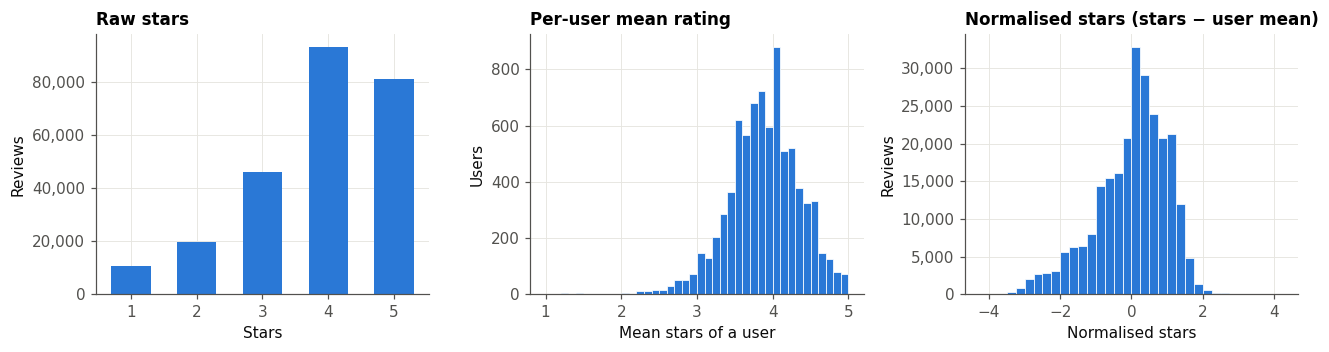

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
vc = rv.stars.value_counts().sort_index()
axes[0].bar(vc.index, vc.values, width=0.6, color=BLUE)
axes[0].set(title="Raw stars", xlabel="Stars", ylabel="Reviews")
axes[1].hist(stats_u.mean_stars, bins=40, color=BLUE, edgecolor="white", linewidth=0.5)
axes[1].set(title="Per-user mean rating", xlabel="Mean stars of a user", ylabel="Users")
axes[2].hist(rv.stars_norm, bins=np.arange(-4.25, 4.3, 0.25), color=BLUE, edgecolor="white", linewidth=0.5)
axes[2].set(title="Normalised stars (stars − user mean)", xlabel="Normalised stars", ylabel="Reviews")
for ax in axes:
    ax.yaxis.set_major_formatter(matplotlib.ticker.StrMethodFormatter("{x:,.0f}"))
fig.tight_layout()
fig.savefig(FIGURES / "01_star_normalisation.png")
plt.show()

> **What we found.** Even among active users the per-user mean rating varies a lot. The average user mean is 3.88 stars, but individual means range from 1 to 5. Two users can therefore give the same 4 stars with opposite meanings, and this is exactly what the normalisation corrects.
>
> After centring, ratings spread roughly from −3.9 to +3.8 around 0, with a longer **negative tail**: a user's bad experiences stand out more strongly from their usual rating than their good ones. 57% of reviews are above the user's own mean.
>
> Only 36 users (0.5%) rate everything the same. We keep them, since their restaurant sets are still informative.

## 1f. A first look at the cleaned data

Three properties of the cleaned data matter directly for the later steps:
- **Reviews per user**: the size of each user's taste set (step 3, MinHash).
- **Friend degree**: how dense the graph is that Louvain will partition (step 2).
- **Reviewers per restaurant**: if most restaurants are reviewed by only one kept user, user–restaurant sets overlap little, so Jaccard similarities will be small. That is an argument for also trying **categories (cuisines)** instead of restaurants in step 3.

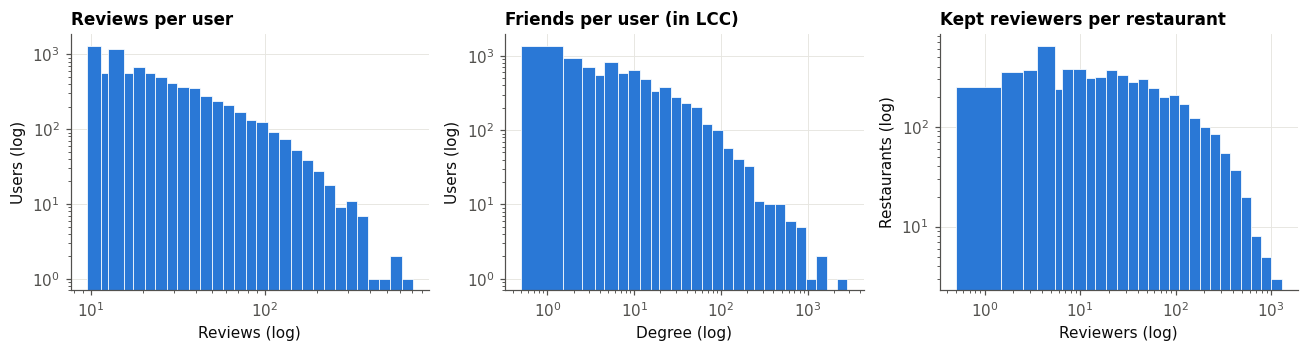

Reviews per user : median 19, mean 31.6, max 706
Friend degree    : median 5, mean 17.0, max 2,832; graph density 2.14e-03
Restaurants reviewed by exactly 1 kept user: 4.4% (they hold 0.1% of reviews)


In [16]:
def int_log_bins(max_value, start=1, n=30):
    # Log-spaced bin edges rounded to integers (avoids empty bins for small integer values).
    return np.unique(np.round(np.logspace(np.log10(start), np.log10(max_value + 1), n))) - 0.5

deg = pd.Series(dict(G.degree()), name="degree")
reviewers_per_biz = rv.groupby("business_id").size()

fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
axes[0].hist(stats_u.n_reviews, bins=int_log_bins(stats_u.n_reviews.max(), start=MIN_REVIEWS), color=BLUE, edgecolor="white", linewidth=0.5)
axes[0].set(xscale="log", yscale="log", title="Reviews per user", xlabel="Reviews (log)", ylabel="Users (log)")
axes[1].hist(deg, bins=int_log_bins(deg.max()), color=BLUE, edgecolor="white", linewidth=0.5)
axes[1].set(xscale="log", yscale="log", title="Friends per user (in LCC)", xlabel="Degree (log)", ylabel="Users (log)")
axes[2].hist(reviewers_per_biz, bins=int_log_bins(reviewers_per_biz.max()), color=BLUE, edgecolor="white", linewidth=0.5)
axes[2].set(xscale="log", yscale="log", title="Kept reviewers per restaurant", xlabel="Reviewers (log)", ylabel="Restaurants (log)")
fig.tight_layout()
fig.savefig(FIGURES / "01_cleaned_distributions.png")
plt.show()

print(f"Reviews per user : median {stats_u.n_reviews.median():.0f}, "
      f"mean {stats_u.n_reviews.mean():.1f}, max {stats_u.n_reviews.max():,}")
print(f"Friend degree    : median {deg.median():.0f}, mean {deg.mean():.1f}, max {deg.max():,}; "
      f"graph density {nx.density(G):.2e}")
print(f"Restaurants reviewed by exactly 1 kept user: {(reviewers_per_biz == 1).mean():.1%} "
      f"(they hold {reviewers_per_biz[reviewers_per_biz == 1].sum() / len(rv):.1%} of reviews)")

> **What we found.** All three distributions are **heavy-tailed**:
> - **Reviews per user**: the median user has 19 restaurant reviews, the mean is 32 and the maximum is 706.
> - **Friends per user**: the median user has 5 friends in the LCC, but a few hub users have thousands (max 2,832). The graph is sparse (density 2.1·10⁻³), which suits Louvain. Hubs can glue communities together, so step 2 should look at them.
> - **Reviewers per restaurant**: only 4.4% of restaurants are reviewed by a single kept user, holding 0.1% of the reviews. The user–restaurant sets therefore overlap well, and Jaccard/MinHash should find meaningful similar pairs.

In [17]:
# Categories of the kept restaurants (what steps 3–4 can use instead of restaurant IDs).
# The scope tag itself ("Restaurants") is on every business now, so it carries no information:
# `categories_taste` is the category list without it.
biz_city = biz[biz.business_id.isin(rv.business_id)].copy()
biz_city["categories_taste"] = biz_city["categories_list"].map(lambda cs: [c for c in cs if c != BUSINESS_CATEGORY])

user_cats = (rv[["user_id", "business_id"]]
             .merge(biz_city[["business_id", "categories_taste"]], on="business_id")
             .explode("categories_taste").dropna(subset=["categories_taste"])
             .drop_duplicates(["user_id", "categories_taste"]))
cats_per_user = user_cats.groupby("user_id").size()
cat_table = pd.DataFrame({
    "restaurants": Counter(c for cs in biz_city.categories_taste for c in cs),
    "share_of_users": user_cats.groupby("categories_taste").size() / rv.user_id.nunique(),
}).sort_values("share_of_users", ascending=False)

print(f"Distinct categories among kept restaurants (without '{BUSINESS_CATEGORY}'): {len(cat_table):,}")
print(f"Distinct categories per user: median {cats_per_user.median():.0f}, mean {cats_per_user.mean():.0f}")
print(f"Categories reached by > 50% of users: {(cat_table.share_of_users > 0.5).sum()}, "
      f"> 25%: {(cat_table.share_of_users > 0.25).sum()}")
closed = biz_city.loc[biz_city.is_open == 0, "business_id"]
print(f"Closed restaurants (is_open = 0): {len(closed) / len(biz_city):.1%} of restaurants, "
      f"{rv.business_id.isin(closed).mean():.1%} of reviews (kept: the reviews still show taste)")
cat_table.head(25).style.format({"restaurants": "{:,}", "share_of_users": "{:.1%}"})

Distinct categories among kept restaurants (without 'Restaurants'): 374
Distinct categories per user: median 48, mean 55
Categories reached by > 50% of users: 36, > 25%: 74
Closed restaurants (is_open = 0): 39.9% of restaurants, 28.6% of reviews (kept: the reviews still show taste)


,restaurants,share_of_users
Food,"1,864",99.3%
Nightlife,"1,025",97.7%
Bars,974,97.4%
American (New),744,95.6%
Breakfast & Brunch,682,94.0%
American (Traditional),652,91.9%
Sandwiches,916,89.9%
Italian,501,83.3%
Coffee & Tea,570,80.5%
Pizza,778,78.7%


> **What we found.** Without the `Restaurants` tag, the kept restaurants carry **374 categories**, and the median user touches 48 of them.
>
> Even within restaurants, Yelp's category list mixes **cuisines** (`Italian`, `Chinese`, `Mexican`, `Vegetarian`, …) with **generic tags** (`Food` 99% of users, `Nightlife` 98%, `Bars` 97%, `Event Planning & Services` 67%). **36 categories reach more than half of all users.** Category sets are therefore dense, and Jaccard similarity on them will be high for nearly everyone.
>
> For category-based taste (steps 3–4) we should **drop the most widespread categories**, for example those reaching more than 50% of users. Restaurant-level sets (`business_id`) are the cleaner primary representation.
>
> Closed restaurants are 40% of restaurants and 29% of reviews. We keep them: a review of a now-closed restaurant still shows what the user liked.

## 1g. Sanity checks and saving

Before saving, we **assert** the properties that later steps rely on. If any of them fails, the notebook stops here instead of silently passing bad data on.

In [18]:
kept_users = set(rv.user_id)
assert kept_users == set(G.nodes), "users in reviews and in the graph must be identical"
assert nx.is_connected(G), "the friendship graph must be one connected component"
assert rv.groupby("user_id").size().min() >= MIN_REVIEWS, "every user needs >= MIN_REVIEWS reviews"
assert not rv.duplicated(["user_id", "business_id"]).any(), "one review per (user, business)"
assert rv.business_id.isin(city_biz).all(), "all businesses are in the chosen city"
assert rv.business_id.isin(scope_ids).all(), "all businesses are restaurants"
assert (rv.is_positive == (rv.stars >= POSITIVE_MIN_STARS)).all(), "is_positive follows the threshold"
assert rv.stars.between(1, 5).all(), "stars are in 1..5"
assert np.allclose(rv.groupby("user_id").stars_norm.mean(), 0, atol=1e-5), "normalised ratings average 0 per user"
assert kept_users <= set(users_cand.user_id), "every kept user has a profile in the user file"
print("All checks passed.")

All checks passed.


We save four tables, prefixed with the city (`<city>` = the `CITY_SLUG` printed above):

| File | One row per | Columns |
|---|---|---|
| `<city>_users.parquet` | user in the LCC | `user_id`, `n_reviews`, `n_positive`, `mean_stars`, `std_stars` (from the cleaned reviews), `degree` (friends in the LCC), and profile fields from the user file: `yelp_review_count`, `yelping_since`, `fans`, `yelp_average_stars` |
| `<city>_friend_edges.parquet` | undirected friendship | `u`, `v` with `u < v` |
| `<city>_reviews.parquet` | (user, restaurant) | `user_id`, `business_id`, `stars`, `stars_norm`, `is_positive` (stars ≥ 3.5), `date` |
| `<city>_businesses.parquet` | restaurant with ≥ 1 kept review | `business_id`, `name`, `city`, `state`, `latitude`, `longitude`, `stars`, `review_count`, `is_open`, `categories` (full list), `categories_taste` (without `Restaurants`), `n_reviews_clean` |

`cleaning_summary.json` records the parameters and the counts after every filter, so the report can quote them.

In [19]:
users_out = (stats_u.loc[sorted(kept_users)]
             .join(pos_per_user.rename("n_positive"))
             .join(deg)
             .join(users_cand.set_index("user_id")[["review_count", "yelping_since", "fans", "average_stars"]]
                   .rename(columns={"review_count": "yelp_review_count", "average_stars": "yelp_average_stars"}))
             .reset_index().rename(columns={"index": "user_id"}))
users_out["yelping_since"] = pd.to_datetime(users_out["yelping_since"])

edges_out = pd.DataFrame([tuple(sorted(e)) for e in G.edges()], columns=["u", "v"]).sort_values(["u", "v"])

reviews_out = rv[["user_id", "business_id", "stars", "stars_norm", "is_positive", "date"]].sort_values(["user_id", "date"])

biz_out = (biz_city[["business_id", "name", "city_norm", "state", "latitude", "longitude",
                     "stars", "review_count", "is_open", "categories_list", "categories_taste"]]
           .rename(columns={"categories_list": "categories"})
           .assign(city=city_name)            # canonical name (merges the spelling variants)
           .drop(columns="city_norm")
           .merge(reviewers_per_biz.rename("n_reviews_clean"), left_on="business_id", right_index=True))

outputs = {"users": users_out, "friend_edges": edges_out, "reviews": reviews_out, "businesses": biz_out}
for name, df in outputs.items():
    path = DATA_PROCESSED / f"{CITY_SLUG}_{name}.parquet"
    df.to_parquet(path, index=False)
    print(f"{path.relative_to(PROJECT_ROOT)}: {len(df):,} rows x {df.shape[1]} cols, {path.stat().st_size / 1e6:.1f} MB")

summary = {
    "city": CITY, "business_category": BUSINESS_CATEGORY, "min_reviews": MIN_REVIEWS,
    "positive_min_stars": POSITIVE_MIN_STARS, "seed": SEED,
    "dedup_rule": "keep most recent review per (user, business)",
    "normalisation": "stars_norm = stars - mean stars of the user over the cleaned reviews",
    "positive": f"is_positive = stars >= {POSITIVE_MIN_STARS}",
    "funnel": (funnel_df.drop(columns="users_kept_vs_prev").reset_index()
               .astype(object).where(lambda d: d.notna(), None).to_dict(orient="records")),
    "final": {"users": len(users_out), "friend_edges": len(edges_out),
              "reviews": len(reviews_out), "businesses": len(biz_out)},
}
(DATA_PROCESSED / "cleaning_summary.json").write_text(json.dumps(summary, indent=2, default=str))
print("data/processed/cleaning_summary.json written")

data/processed/philadelphia_pa_users.parquet: 7,947 rows x 10 cols, 0.4 MB
data/processed/philadelphia_pa_friend_edges.parquet: 67,622 rows x 2 cols, 0.4 MB
data/processed/philadelphia_pa_reviews.parquet: 251,375 rows x 6 cols, 3.3 MB
data/processed/philadelphia_pa_businesses.parquet: 5,759 rows x 12 cols, 0.4 MB
data/processed/cleaning_summary.json written


### How later steps load the clean data
```python
import pandas as pd, networkx as nx
P = "data/processed/<city>_"            # e.g. the CITY_SLUG printed above
users   = pd.read_parquet(P + "users.parquet")
edges   = pd.read_parquet(P + "friend_edges.parquet")
reviews = pd.read_parquet(P + "reviews.parquet")
biz     = pd.read_parquet(P + "businesses.parquet")
G = nx.from_pandas_edgelist(edges, "u", "v")                        # step 2: Louvain
user_sets = reviews.groupby("user_id")["business_id"].agg(set)      # step 3: MinHash/LSH
baskets = reviews[reviews.is_positive].groupby("user_id")["business_id"].agg(list)   # step 4 (restaurants)
cuisine_of = biz.set_index("business_id")["categories_taste"]                     # step 4 (cuisines)
```

## Summary of step 1

**Final cleaned dataset (Philadelphia, PA):**

| | Count |
|---|---|
| Users (all with ≥ 10 restaurant reviews, all in one friend component) | 7,947 |
| Friendships (undirected) | 67,622 |
| Reviews (one per user–restaurant, with normalised stars and `is_positive`) | 251,375 |
| Restaurants | 5,759 |

### Decision log

| # | Decision | Reason / evidence |
|---|---|---|
| 1 | **Restaurants only** (businesses tagged `Restaurants`), applied before the activity filter | Makes "taste" concrete (food preferences) and avoids users looking similar because of shared services (dentists, car repair). Restaurants account for 68% of all reviews. *Team decision.* |
| 2 | City = **Philadelphia, PA** | Largest friend-graph LCC after filtering (≈ 7.9k users vs ≈ 3.4k for the next city); most active restaurant reviewers (10.7k). |
| 3 | A city is identified by (normalised name, state); misspelled city names are merged into Philadelphia | Free-text city field; variants listed in 1c; impact negligible (1 extra restaurant). |
| 4 | One review per (user, restaurant): keep the **most recent** | 40,876 repeat reviews in 19,331 pairs; repeats would let a user reach the threshold by reviewing one place repeatedly. |
| 5 | Users with **≥ 10 distinct restaurants reviewed in Philadelphia** (not Yelp's `review_count` field) | Taste sets must be large enough for stable Jaccard similarities and per-user means; `review_count` includes reviews outside the dataset, the city and restaurants. |
| 6 | Treat friendship as **undirected** | 100% of friend links are reciprocated. |
| 7 | Keep the **LCC of the friend graph built after the activity filter** | 74% of active users are in it; all other components have ≤ 3 users (2,725 isolated users). |
| 8 | `stars_norm = stars − user mean` over the cleaned reviews; constant raters (36) kept | Per-user means range from 1 to 5; centring separates taste from rating habit. |
| 9 | **Positive rating = stars ≥ 3.5**, i.e. 4 or 5 stars (`is_positive`) | Simple and easy to explain; 69.5% of reviews; only 16 users have fewer than 2 positives. Agrees with `stars_norm > 0` on 86.5% of reviews. *Team decision.* |
| 10 | Keep **closed restaurants** | 29% of reviews; they still show what users like. |
| 11 | Drop the review `text`, tips and check-ins | Not needed for the research question; this saves memory and time. |

### Notes for the next steps
- **Step 2 (friend communities):** load `philadelphia_pa_friend_edges.parquet`. A handful of hub users have more than 1,000 friends, so check whether they dominate any community.
- **Step 3 (taste communities):** restaurant sets overlap well (only 4% of restaurants have a single kept reviewer), so they are a good primary representation. For category sets, use `categories_taste` and drop the most widespread tags (36 reach more than 50% of users) before MinHash/LSH.
- **Step 4 (baskets):** baskets are the restaurants (or `categories_taste` of the restaurants) with `is_positive == True`. Skip the 16 users with fewer than 2 positive items.
- **Limitations to report:** the filters keep the most active and socially connected users (selection bias); the absolute positive threshold is lenient for generous raters; friendships have no timestamps; one city may not generalise.